In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import xarray as xr
import scipy.stats as stats
import matplotlib.pyplot as plt
import tqdm as tqdm
import sklearn 
import pickle

from scipy.integrate import simpson
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm

In [2]:
"""import pickle
with open(r"/data/keeling/a/cstraus2/Phd_research/Apr_2_Oct_Station_events_data_multidf_negdeltas_del_normalized_delta_perPtot_roundedhundredths.pkl", "rb") as f:
   Apr_2_Oct_Station_events_dict_oldnorm = pickle.load(f)"""

'import pickle\nwith open(r"/data/keeling/a/cstraus2/Phd_research/Apr_2_Oct_Station_events_data_multidf_negdeltas_del_normalized_delta_perPtot_roundedhundredths.pkl", "rb") as f:\n   Apr_2_Oct_Station_events_dict_oldnorm = pickle.load(f)'

In [3]:
with open(r"/data/keeling/a/cstraus2/Phd_research/Apr_2_Oct_Station_events_data_multidf_negdeltas_del_normalized_priorpeaktogether2_delta_perPtot.pkl", "rb") as f:
   Apr_2_Oct_Station_events_dict = pickle.load(f)

In [3]:
station_lengths = {station: len(df) for station, df in Apr_2_Oct_Station_events_dict.items()}
for station, df in Apr_2_Oct_Station_events_dict.items():
    print(f"{station}: {len(df)} rows")

bbc: 645 rows
brw: 550 rows
bvl: 555 rows
cmi: 657 rows
dek: 672 rows
dxs: 578 rows
fai: 582 rows
fre: 610 rows
frm: 581 rows
icc: 603 rows
llc: 578 rows
mon: 652 rows
oln: 603 rows
orr: 568 rows
rnd: 570 rows
sfm: 178 rows
siu: 587 rows
sni: 278 rows
stc: 669 rows
ste: 576 rows


# KDE cannot handle NaN or inf, so events that have NaN sm due to impossible values need to be dropped
there are likely nan values in the other sm columns like max, sum, etc but the .max() function ignores those so only events where the prior sm=nan need to be droppped but sm = nan during a storm event could mean the sensor is erroneous for the event. For now they are kept


### PDF estimation with KDE, binwidth method options are scott or silvermann, using scott's method as it is more robust for non-normally distributed data with skewness, which is precip data
https://ntnuopen.ntnu.no/ntnu-xmlui/bitstream/handle/11250/258553/348940_FULLTEXT01.pdf?sequence=1&isAllowed=y
https://www.umiacs.umd.edu/labs/cvl/pirl/vikas/publications/optimal_bw_slides.pdf

Goodwell and Kumar used Silverman it seems based on their citations of Silverman

set up pdf_generation function to be expandable to any number of columns (1st time through we are only using sm for 10 cm and 100cm)
also set up to be expandable to the number of stations incase we were to give this more station data from other states

In [4]:
#trivariate kde first
def pdf_generation_trifirst(data,bw_scale):

    kde_combined_results =[]
    column_min_max_values = []
    band_widths_tri_vals = []
    
    #iterate through each station's data
    for s, df in data.items():
        #s is the station key in the dictionary and df is specific dataframe 
        #calculate individual kdes
        print('Station:', s)
        #df=df.dropna()

        #calculate trivariate kdes between deltas/ptot, peakP, prior sm 
        P_data = df.loc[:,df.columns.str.contains('Precipitation', regex = True)]
        prior_sm_data = df.loc[:,df.columns.str.contains('Prior', regex = True)]
        
        for i_P in range (P_data.shape[1]):
            P_data_i = P_data.iloc[:, i_P]
            P_col_label = P_data_i.name
            if 'Total' in P_col_label: #don't calc for delta/ptot with total P, so change delta cols pulled
                deltas_data = df.loc[:,df.columns.str.contains('Delta') & 
                                        ~df.columns.str.contains('Ptot')]
            else:
                deltas_data = df.loc[:,df.columns.str.contains('Delta', regex = True)]
            for i_sm in range(prior_sm_data.shape[1]):
                prior_sm_data_i = prior_sm_data.iloc[:,i_sm]
                prior_sm_col_label = prior_sm_data_i.name
                for j_Ptot in range(deltas_data.shape[1]):
                    deltas_Ptot_j = deltas_data.iloc[:, j_Ptot]
                    deltas_Ptot_col_label = deltas_Ptot_j.name
                    multi_data = np.vstack([
                        P_data_i.values, prior_sm_data_i.values, deltas_Ptot_j.values
                                        ])
                    tri_kde = stats.gaussian_kde(multi_data, bw_method = 'scott')
                    tri_kde.set_bandwidth(bw_method = tri_kde.scotts_factor() * bw_scale)
                    tri_kde_bw_x = tri_kde.factor * np.sqrt(tri_kde.covariance[0,0])
                    tri_kde_bw_y = tri_kde.factor * np.sqrt(tri_kde.covariance[1,1])
                    tri_kde_bw_z = tri_kde.factor * np.sqrt(tri_kde.covariance[2,2])
                    tri_bw = [tri_kde_bw_x, tri_kde_bw_y, tri_kde_bw_z]
                    trivar_label = f'trivar_kde_{P_col_label}_{prior_sm_col_label}_{deltas_Ptot_col_label}'
                    kde_combined_results.append((s, trivar_label, tri_kde, 'trivariate'))
                    band_widths_tri_vals.append((s, tri_bw, trivar_label))


        #iterate through each column in the station's data
        for col in df.columns:
            #print('column', df[col])
            #print('nan?',df[col].isna().sum())
            #print('inf?',np.isinf(df[col]).sum())
            col_min = np.round(df[col].min(), decimals=2)
            col_max = np.round(df[col].max(), decimals=2)
            column_min_max_values.append((s, col, col_min, col_max))

            
    #check shape of combined dataframe
    #for i, item in enumerate(kde_combined_results):
    #    print(f"Item {i}: length = {len(item)}, content = {item}")

    #convert results into a multiIndex df
    multi_kde_df = pd.DataFrame(kde_combined_results, columns = ['Station', 'Variable', 'KDE_Object', 
                                                                 'Type'])
    multi_kde_df.set_index(['Station', 'Variable', 'Type'], inplace = True)

    min_max_df = pd.DataFrame(column_min_max_values, columns=['Station', 'Variable', 'Min', 'Max'])
    min_max_df.set_index(['Station', 'Variable'], inplace=True)
    
    band_widths_tri_df = pd.DataFrame(band_widths_tri_vals, columns = ['Station', 'bandwidth', 
                                                                       'Variable'])
    
    return multi_kde_df, min_max_df, band_widths_tri_df


In [5]:
#for band width scale, <1 shrinks the bandwidth >1 widens it causing more smoothing

Apr_2_Oct_multi_station_kdes, Apr_2_Oct_multi_station_min_max_df, Apr_2_Oct_multi_station_trivar_bw = pdf_generation_trifirst(Apr_2_Oct_Station_events_dict, bw_scale = 1) 

Station: bbc
Station: brw
Station: bvl
Station: cmi
Station: dek
Station: dxs
Station: fai
Station: fre
Station: frm
Station: icc
Station: llc
Station: mon
Station: oln
Station: orr
Station: rnd
Station: sfm
Station: siu
Station: sni
Station: stc
Station: ste


Note that the code above creates a dataframe of KDE objects that are indexed by station ids. 
After using .loc['station_id', 'KDE_Object'] you get a pandas.Series that is multiIndexed which looks like columns
so the 'Column' and 'Type' columns are actually indices which sort the kde_objects

using pandas.Series allows for easier label-based filtering for grouping and selection which is
better than a dictionary where you select via the key name

so for selection the following is needed rather than the typical .loc[] for a dataframe
 kde_Series = kde_dict_data.loc[(s, 'KDE_Object')]

        individuals_kde = kde_Series[kde_Series.index.get_level_values(1) == 'individual']


# Calculating shannon's entropy and then the mutual information

shannon's entropy, H(X) = sum(p(x_i)*log(1/p(x_i))) = -sum(p(x_i)*log(p(x_i)))

Very small (e.g., < 1e-12) can cause log2(p) to explode negatively causing numerical instability in 
entropy estimations. Mask values below this to prevent the instability. Also set the dx and dy to have a floor of 0.001
to also avoid too small of probabilties. the log2(p_x) goes to -inf when it get small

mask out p(x) <=1e-12 to avoid the numerical instability or simply add 1e-12 to all the p(x) values, 
technically a shortcut, but common and since we are interested in the ratio of comparing the entropy and mi values and not their absolute values this is very defensible.

value this small are negligible to the total entropy but create major instability due to log2(0) -> -inf

for accurate capture of the pdf, the edge mass for the marginals needs to be 1e-5 for the joint it needs to be smaller 1e-6

dx for marginal needs to be around 0.001 for joint because the calculation is over a grid cell (area) the dx=dy needs to be larger. 
if grid cell resolution is too fine you get over estimation of joint, if it is too large you get under estimation. having dx and dy =0.001 gives an area of 1e-6 

mutual information, I(x,y) = H(x) - H(x|y) or H(y) - H(y|x) 
### or H(x) + H(y) - H(x,y)

normalized MI: Cxy = I(x,y)/H(y) and Cyx = I(x,y)/H(x)



H(x,y)min >= max(H(x), H(y))

MI <= min(H(x), H(y))


In [6]:
def calc_entropy_trifirst(kde_df_Series_data, min_max_df,var_bw):
    entropies = {}
    kde_df_Series_data = kde_df_Series_data.sort_index() 
    resolution_num = 31 #must be an odd number so there are even number of intervals for the simpsons rule integration <- normalization has been removed
    n_bw = 15
    
    for s, group in kde_df_Series_data.groupby(level = 'Station'):
        print(s)

        station_kde_Series = kde_df_Series_data.loc[(s, 'KDE_Object')]
        n_rows = len(station_kde_Series)
        station_entropy_values = {}
        
        station_cols_min_vals = min_max_df.Min.loc[s]
        station_cols_max_vals = min_max_df.Max.loc[s]
        keep_vars = station_cols_min_vals.index.str.contains('Precipitation|Prior|Delta', regex = True)
        filtered_min_vals = station_cols_min_vals[keep_vars]
        filtered_max_vals = station_cols_max_vals[keep_vars]

        #print(f"Filtered min values: {filtered_min_vals}")
        #print(f"Filtered max values: {filtered_max_vals}")

        if filtered_min_vals.empty or filtered_max_vals.empty:
            print(f"⚠️ No valid min/max values for {s}")
            continue
               
        for (tri_label, trivar_kde_obj) in station_kde_Series.items():
            #print(f"Processing tri KDE for {tri_label}")
            tri_kde_name = tri_label[0].replace("trivar_kde_", "")
            delta_var_label = tri_kde_name[tri_kde_name.find('Delta'):]
            prior_var_label = tri_kde_name[tri_kde_name.find('Prior'):tri_kde_name.find('_Delta')]
            P_var_label = tri_kde_name[:tri_kde_name.find('_Prior')]
            try:
                x_min = filtered_min_vals[P_var_label]
                x_max = filtered_max_vals[P_var_label]
                y_min = filtered_min_vals[prior_var_label]
                y_max = filtered_max_vals[prior_var_label]
                z_min = filtered_min_vals[delta_var_label]
                z_max = filtered_max_vals[delta_var_label]

            except KeyError:
                print(f"⚠️ Could not find min/max for some variable")
                continue
                    
            var_bw_row = var_bw.loc[(var_bw['Station'] == s) & 
                                              (var_bw['Variable'] == tri_label[0])]
                    
            x_tri_bw, y_tri_bw, z_tri_bw = var_bw_row['bandwidth'].values[0]
                    
            x_vals_P = np.linspace(x_min - x_tri_bw*n_bw, x_max + x_tri_bw*n_bw, resolution_num) 
            dx = x_vals_P[1]-x_vals_P[0]
                    
            y_vals_prior = np.linspace(y_min - y_tri_bw*n_bw, y_max + y_tri_bw*n_bw, resolution_num)
            dy = y_vals_prior[1]-y_vals_prior[0]

            z_vals_delta = np.linspace(z_min - z_tri_bw*n_bw, z_max + z_tri_bw*n_bw, resolution_num)
            dz = z_vals_delta[1]-z_vals_delta[0]

            #pair data in meshgrd and flatten to 3xN array for kde
            X_P, Y_priorsm, Z_deltaPtot =np.meshgrid(x_vals_P, y_vals_prior,z_vals_delta, 
                                                     indexing = 'ij')
            positions = np.vstack([X_P.ravel(), Y_priorsm.ravel(), Z_deltaPtot.ravel()])
            densities = np.reshape(trivar_kde_obj(positions), X_P.shape) #(x,y,z) = (P, prior, delta)
            
            print('pre-normalized D3_pdf', np.sum(densities * dx * dy * dz))


            # Normalize the density (integrate over all grid points (triple integral))
            #triple_integral = simpson(simpson(simpson(densities, dx=dz, axis = 2), dx = dy, axis = 1), dx=dx, axis = 0) #should sum to 1
            D3_pdf = densities #/ triple_integral  # Normalize to get probability distribution
            #print('normalized D3_pdf', np.sum(D3_pdf * dx * dy * dz))

            edge_vals = np.concatenate([
                    D3_pdf[0, :, :].ravel(), D3_pdf[-1, :, :].ravel(),  # Top and bottom edges
                    D3_pdf[:, 0, :].ravel(), D3_pdf[:, -1, :].ravel(),  # Left and right edges
                    D3_pdf[:, :, 0].ravel(), D3_pdf[:, :, -1].ravel()]) # Front and back edges
            max_edge_density = np.max(edge_vals)
            print(f"🔍 Max density on edges of tri PDF between {P_var_label} and {prior_var_label} and {delta_var_label}: {max_edge_density:.2e}")
            if max_edge_density > 1e-5:
                print("⚠️ Significant density near the edge — consider extending x/y/z " \
                "ranges further,  ideally edge range below 1e-5")

            print('dx,dy,dz', (dx,dy,dz))
            print('bin num for tri', resolution_num)

            # Compute joint probabilities using dx * dy integration
            D3_pvals = D3_pdf * dx * dy * dz  # Discretized probability mass function
            print('total mass = ', np.sum(D3_pvals)) #should be very close to 1

            # Compute log2 probabilities, avoiding log(0) by masking zeros
            D3_pvals_flat = D3_pvals.ravel()
            if np.any(D3_pvals_flat <= 0):
                print("Warning: PDF has near-zero or negative values")

            #add to small probabilities to stabilize the log of the small values in tails
            eps = 1e-12  
            log2_pvals = np.log2(D3_pvals_flat + eps)

            # Calculate trivar entropy
            H_tri = np.round(-np.sum(D3_pvals_flat * log2_pvals), decimals = 3)
            if np.isnan(H_tri) or np.isinf(H_tri):
                print("Entropy result is unstable")

            print(f'trivariate entropy between {P_var_label} and {prior_var_label} and {delta_var_label}: {H_tri}')
            station_entropy_values[f'trivariate_entropy_{P_var_label}_{prior_var_label}_{delta_var_label}'] = H_tri

            #calculate the joint pdf by summing along the joint axes
            #(x,y,z) = (P, prior, delta)
            #the following are densities
            joint_P_prior_pdf = np.sum(D3_pdf, axis = 2) * dz
            print('Check ∫pXY =', np.sum(joint_P_prior_pdf * dx * dy))
            joint_prior_delta_pdf = np.sum(D3_pdf, axis = 0) * dx
            print('Check ∫pXY =', np.sum(joint_prior_delta_pdf * dy * dz))
            joint_P_delta_pdf = np.sum(D3_pdf, axis = 1) * dy
            print('Check ∫pXY =', np.sum(joint_P_delta_pdf * dx * dz))

            #joint_P_prior_pdf /= np.sum(joint_P_prior_pdf * dx * dy)
            #joint_prior_delta_pdf /= np.sum(joint_prior_delta_pdf * dy * dz)
            #joint_P_delta_pdf /= np.sum(joint_P_delta_pdf * dx * dz)

            #calculate the joint entropies
            #calc the probabilities
            joint_P_prior_pvals = joint_P_prior_pdf * dx * dy
            joint_prior_delta_pvals = joint_prior_delta_pdf * dy * dz
            joint_P_delta_pvals = joint_P_delta_pdf * dx * dz

            joint_P_prior_pvals = joint_P_prior_pvals.ravel()
            joint_prior_delta_pvals = joint_prior_delta_pvals.ravel()
            joint_P_delta_pvals = joint_P_delta_pvals.ravel()

            H_P_prior = -np.sum(joint_P_prior_pvals * np.log2(joint_P_prior_pvals + eps))
            H_prior_delta = -np.sum(joint_prior_delta_pvals * np.log2(joint_prior_delta_pvals + eps))
            H_P_delta = -np.sum(joint_P_delta_pvals * np.log2(joint_P_delta_pvals + eps))

            station_entropy_values[f'joint_entropy_{P_var_label}_{prior_var_label}'] = np.round(H_P_prior, 3)
            station_entropy_values[f'joint_entropy_{prior_var_label}_{delta_var_label}'] = np.round(H_prior_delta, 3)
            station_entropy_values[f'joint_entropy_{P_var_label}_{delta_var_label}'] = np.round(H_P_delta, 3)

            #individual pdfs
            P_pdf = np.sum(np.sum(D3_pdf, axis = 2), axis =1) * dy * dz
            print('Check ∫pX =', np.sum(P_pdf * dx ))
            prior_pdf = np.sum(np.sum(D3_pdf, axis = 2), axis =0) * dx * dz
            print('Check ∫pY =', np.sum(prior_pdf * dy ))
            delta_pdf = np.sum(np.sum(D3_pdf, axis = 1), axis =0) * dx * dy
            print('Check ∫pZ =', np.sum(delta_pdf * dz ))

            #P_pdf /= np.sum(P_pdf * dx)
            #prior_pdf /= np.sum(prior_pdf * dy)
            #delta_pdf /= np.sum(delta_pdf * dz)

            #calculate ind probabilites
            P_pvals = P_pdf * dx
            prior_pvals = prior_pdf * dy
            delta_pvals = delta_pdf * dz

            H_P = -np.sum(P_pvals * np.log2(P_pvals + eps))
            H_prior = -np.sum(prior_pvals * np.log2(prior_pvals + eps))
            H_delta = -np.sum(delta_pvals * np.log2(delta_pvals + eps))

            station_entropy_values[f'individual_entropy_{P_var_label}'] = np.round(H_P, 3)
            station_entropy_values[f'individual_entropy_{prior_var_label}'] = np.round(H_prior, 3)
            station_entropy_values[f'individual_entropy_{delta_var_label}'] = np.round(H_delta, 3)

        if station_entropy_values:
            entropy_df = pd.DataFrame([station_entropy_values])  # one row
            entropies[s] = entropy_df
        else:
            print(f"⚠️ No entropy values computed for station {s}")
    return entropies

In [7]:
Entropies = calc_entropy_trifirst(Apr_2_Oct_multi_station_kdes, Apr_2_Oct_multi_station_min_max_df, Apr_2_Oct_multi_station_trivar_bw)

bbc
pre-normalized D3_pdf 1.0000013783374173
🔍 Max density on edges of tri PDF between Avg_Precipitation_rate_in and Prior_sm_100 and Delta_sm_10: 3.64e-07
dx,dy,dz (0.04899554245413287, 0.05872600234801162, 0.0627462554411164)
bin num for tri 31
total mass =  1.0000013783374173
trivariate entropy between Avg_Precipitation_rate_in and Prior_sm_100 and Delta_sm_10: 9.581
Check ∫pXY = 1.0000013783374175
Check ∫pXY = 1.0000013783374175
Check ∫pXY = 1.0000013783374175
Check ∫pX = 1.0000013783374173
Check ∫pY = 1.0000013783374173
Check ∫pZ = 1.0000013783374173
pre-normalized D3_pdf 1.0000013783390391
🔍 Max density on edges of tri PDF between Avg_Precipitation_rate_in and Prior_sm_100 and Delta_sm_100: 5.02e-07
dx,dy,dz (0.04899554245413287, 0.05872600234801162, 0.05950017914209926)
bin num for tri 31
total mass =  1.0000013783390391
trivariate entropy between Avg_Precipitation_rate_in and Prior_sm_100 and Delta_sm_100: 9.462
Check ∫pXY = 1.0000013783390393
Check ∫pXY = 1.0000013783390393
Ch

In [7]:
Entropies['cmi']

,trivariate_entropy_Avg_Precipitation_rate_in_Prior_sm_100_Delta_sm_10,joint_entropy_Avg_Precipitation_rate_in_Prior_sm_100,joint_entropy_Prior_sm_100_Delta_sm_10,joint_entropy_Avg_Precipitation_rate_in_Delta_sm_10,individual_entropy_Avg_Precipitation_rate_in,individual_entropy_Prior_sm_100,individual_entropy_Delta_sm_10,trivariate_entropy_Avg_Precipitation_rate_in_Prior_sm_100_Delta_sm_100,joint_entropy_Prior_sm_100_Delta_sm_100,joint_entropy_Avg_Precipitation_rate_in_Delta_sm_100,...,trivariate_entropy_Peak_Precipitation_rate_in_Prior_sm_10_Delta_sm_10_perPtot,trivariate_entropy_Total_Precipitation_in_Prior_sm_100_Delta_sm_10,joint_entropy_Total_Precipitation_in_Prior_sm_100,joint_entropy_Total_Precipitation_in_Delta_sm_10,individual_entropy_Total_Precipitation_in,trivariate_entropy_Total_Precipitation_in_Prior_sm_100_Delta_sm_100,joint_entropy_Total_Precipitation_in_Delta_sm_100,trivariate_entropy_Total_Precipitation_in_Prior_sm_10_Delta_sm_10,joint_entropy_Total_Precipitation_in_Prior_sm_10,trivariate_entropy_Total_Precipitation_in_Prior_sm_10_Delta_sm_100
0,8.276,5.253,6.39,5.158,2.073,3.187,3.229,7.985,6.077,4.892,...,8.464,8.113,5.823,4.995,2.664,7.563,4.54,8.119,5.863,7.646


In [25]:
#save data and kde df
import pickle

with open(r"/data/keeling/a/cstraus2/Phd_research/normalized_entropies_scale1_bw15_gridn31_masked_ptot_rounded_trivariate_normadj.pkl", "wb") as f:
    pickle.dump(Entropies, f)

In [ ]:
"""import pickle
with open(r"/data/keeling/a/cstraus2/Phd_research/normalized_entropies_scale1_bw51715_binn1000_200100_masked_ptot_rounded_trivariate.pkl", "rb") as f:
   Entropies= pickle.load(f)"""

# Calculate MI and normalized MI
normalized MI: Cxy = I(x,y)/H(y) and Cyx = I(x,y)/H(x)

In [17]:
def mutual_information_calc(entropies_dict):
    Stations = list(entropies_dict.keys())
    Station_MI = []
    Station_tri_MI =[]

    for s in Stations:
        #print('station', s)
        station_entropy_df = entropies_dict[s]
        # Step 1: Get columns for H(X) and H(Y) (without 'joint_' prefix)
        individual_columns = [col for col in station_entropy_df.columns if ('individual_')  in col]

        # Step 2: Get columns for H(X, Y) (with 'joint_' prefix)
        joint_columns = [col for col in station_entropy_df.columns if 'joint_' in col]

        # Step 3: Get columns for H(X,Y,Z) (with 'trivariate' prefix)
        trivar_columns = [col for col in station_entropy_df.columns if 'trivariate_' in col]

        for joint_col in joint_columns:
            found = False
            joint_label = joint_col.replace('joint_entropy_', '')
            #print('Joint col', joint_col)
            #print('Joint label', joint_label)

            for col_x in individual_columns:
                for col_y in individual_columns:
                    if col_x == col_y:
                        continue  # skip self-pairs

                    # Remove the '_entropy' suffix to get base names
                    col_x_base = col_x.removeprefix('individual_entropy_')
                    col_y_base = col_y.removeprefix('individual_entropy_')

                    expected_joint_col = f"joint_entropy_{col_x_base}_{col_y_base}"

                    if expected_joint_col == joint_col:
                        #print('match found')
                        # Find the corresponding individual entropy columns
                        # Match found — calculate MI
                        H_X = station_entropy_df[col_x].iloc[0]
                        #print('H_X', H_X)
                        H_Y = station_entropy_df[col_y].iloc[0]
                        #print('H_Y', H_Y)
                        H_XY = station_entropy_df[joint_col].iloc[0]
                        #print('H_XY', H_XY)

                        MI = H_X + H_Y - H_XY
                        MI_label = 'MI_'+ col_x_base + '_and_' + col_y_base

                        Cxy = np.round(MI/H_Y, decimals = 3)
                        Cyx = np.round(MI/H_X, decimals = 3)

                        Station_MI.append({
                                "station": s,
                                "MI_label": MI_label,
                                "mutual_information": MI,
                                "H(x)": col_x_base,
                                "C_yx": Cyx,
                                "H(y)": col_y_base,
                                "C_xy": Cxy
                                        })

                        found = True
                        break  # inner loop
                if found:
                    break  # outer loop   
        #print('finished joint and individuals')
        #calculate for trivariate
        for trivar in trivar_columns:
            x_var = trivar[len('trivariate_entropy_'):trivar.find('_Prior')]
            y_var = trivar[trivar.find('Prior'):trivar.find('_Delta')]
            z_var = trivar[trivar.find('Delta'):]

            variable_labels = [x_var, y_var, z_var]
            individual_entropies_labels= ['individual_entropy_' + var for var in variable_labels]
            joint_combintations = [x_var + '_' + y_var, x_var + '_' + z_var, y_var + '_' + z_var]
            joint_entropies_labels = ['joint_entropy_' + var for var in joint_combintations]

            trivariate_entropy_label = trivar

            #H(x,y,z) + H(x) +H (y) + H(z) - H(x,y) - H(x,z) - H(y,z)
            Hx, Hy, Hz = [station_entropy_df[col].iloc[0] for col in individual_entropies_labels]
            Hxy, Hyz, Hxz = [station_entropy_df[col].iloc[0] for col in joint_entropies_labels]
            Hxyz = station_entropy_df[trivariate_entropy_label].iloc[0]

            MI_label = 'trivariate_MI_'+ x_var + '_'+ y_var + '_' + z_var
            Interacting_I = Hxy + Hyz + Hxz - Hxyz - Hx - Hy - Hz  
            #Dependency_corr_I_label   = 'trivariate_DependencyCorr_I_'+ x_var + '_'+ y_var + '_' + z_var
            Dependency_I = Hx + Hy + Hz - Hxyz
            #Conditional_I_label = 'trivariate_Conditional_I_' + z_var + 'given' + x_var + '_'+ y_var
            Joint_MI_xy_to_z = Hz + Hxy - Hxyz
            
            #print(Hxyz)
            #C_tx = np.round(Conditional_I/Hx, decimals = 3)
            #C_ty = np.round(Conditional_I/Hy, decimals = 3)
            C_tz = np.round(Joint_MI_xy_to_z/Hz, decimals = 3)
            
            Station_tri_MI.append({
                                "station": s,
                                "MI_label": MI_label,
                                "Interacting_information": Interacting_I,
                                "Total_shared_information": Dependency_I,
                                "Z_Conditioned_jointMI": Joint_MI_xy_to_z,
                                "H(x)": individual_entropies_labels[0],
                                "H(y)": individual_entropies_labels[1],
                                "H(z)": individual_entropies_labels[2],
                                "C_tz": C_tz,
                                })



    return pd.DataFrame(Station_MI), pd.DataFrame(Station_tri_MI)

In [18]:
MIs, tri_MI = mutual_information_calc(Entropies) 

In [11]:
MIs

,station,MI_label,mutual_information,H(x),C_yx,H(y),C_xy
0,bbc,MI_Avg_Precipitation_rate_in_and_Prior_sm_100,0.013,Avg_Precipitation_rate_in,0.005,Prior_sm_100,0.003
1,bbc,MI_Prior_sm_100_and_Delta_sm_10,0.092,Prior_sm_100,0.024,Delta_sm_10,0.026
2,bbc,MI_Avg_Precipitation_rate_in_and_Delta_sm_10,0.116,Avg_Precipitation_rate_in,0.046,Delta_sm_10,0.033
3,bbc,MI_Prior_sm_100_and_Delta_sm_100,0.044,Prior_sm_100,0.012,Delta_sm_100,0.013
4,bbc,MI_Avg_Precipitation_rate_in_and_Delta_sm_100,0.113,Avg_Precipitation_rate_in,0.045,Delta_sm_100,0.034
...,...,...,...,...,...,...,...
595,ste,MI_Peak_Precipitation_rate_in_and_Prior_sm_10,0.013,Peak_Precipitation_rate_in,0.004,Prior_sm_10,0.003
596,ste,MI_Total_Precipitation_in_and_Prior_sm_100,0.011,Total_Precipitation_in,0.003,Prior_sm_100,0.003
597,ste,MI_Total_Precipitation_in_and_Delta_sm_10,0.728,Total_Precipitation_in,0.223,Delta_sm_10,0.207
598,ste,MI_Total_Precipitation_in_and_Delta_sm_100,0.812,Total_Precipitation_in,0.249,Delta_sm_100,0.243


In [15]:
tri_MI

,station,MI_label,Interacting_information,Total_shared_information,Z_Conditioned_jointMI,H(z),C_tz
0,bbc,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,2.200000e-02,0.243,0.230,individual_entropy_Delta_sm_10,0.066
1,bbc,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,2.100000e-02,0.191,0.178,individual_entropy_Delta_sm_100,0.054
2,bbc,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,-8.881784e-16,0.066,0.053,individual_entropy_Delta_sm_100_perPtot,0.024
3,bbc,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,9.000000e-03,0.109,0.096,individual_entropy_Delta_sm_10_perPtot,0.035
4,bbc,trivariate_MI_Avg_Precipitation_rate_in_Prior_...,2.700000e-02,0.423,0.408,individual_entropy_Delta_sm_10,0.117
...,...,...,...,...,...,...,...
555,ste,trivariate_MI_Peak_Precipitation_rate_in_Prior...,1.900000e-02,0.148,0.135,individual_entropy_Delta_sm_10_perPtot,0.045
556,ste,trivariate_MI_Total_Precipitation_in_Prior_sm_...,9.300000e-02,0.908,0.897,individual_entropy_Delta_sm_10,0.255
557,ste,trivariate_MI_Total_Precipitation_in_Prior_sm_...,8.200000e-02,0.942,0.931,individual_entropy_Delta_sm_100,0.278
558,ste,trivariate_MI_Total_Precipitation_in_Prior_sm_...,1.250000e-01,0.969,0.956,individual_entropy_Delta_sm_10,0.272


In [19]:
#save MIs
MIs.to_csv('MIs_scale1_bw15_gridn_31_normadj.csv')
tri_MI.to_csv('triMI_scale1_bw15_gridn_31_normadj.csv')

In [ ]:
MIs = pd.read_csv('MIs_scale1_bw15_gridn_31_normadj.csv', index_col = 0)
tri_MI = pd.read_csv('triMI_scale1_bw15_gridn_31_normadj.csv', index_col = 0)

normalized MI: Cxy = I(x,y)/H(y) and Cyx = I(x,y)/H(x)

trivariate MI property: |I(x,y,z)| <= min{H(x), H(y), H(z)}

In [9]:
stations = MIs.station.unique()

peak_10_largest = 0
peak_100_largest = 0


for s in stations:
    station_MI = MIs.loc[(MIs['station'] == s)]
    
    sm_10_nopeak_ratios = station_MI[~station_MI.MI_label.str.contains('100') & 
                                             ~station_MI.MI_label.str.contains('MI_Peak_Precipitation_rate_in_and_Prior_sm_10')].iloc[:,3]
    
    sm_100_nopeak_ratios = station_MI[station_MI.MI_label.str.contains('100')& 
                                             ~station_MI.MI_label.str.contains('MI_Peak_Precipitation_rate_in_and_Prior_sm_100')].iloc[:,3]
    
    if (station_MI[station_MI.MI_label.str.contains('MI_Peak_Precipitation_rate_in_and_Prior_sm_10')].iloc[:,3].values[0]) < sm_10_nopeak_ratios.max():
        peak_10_largest += 1

    if (station_MI[station_MI.MI_label.str.contains('MI_Peak_Precipitation_rate_in_and_Prior_sm_100')].iloc[:,3].values[0]) < sm_100_nopeak_ratios.max():
        peak_100_largest += 1
    

print('Peak and prior MI for sm 10 is the smallest MI:', peak_10_largest)
print('Peak and prior MI for sm 100 is the smallest MI:', peak_100_largest)

Peak and prior MI for sm 10 is the smallest MI: 20
Peak and prior MI for sm 100 is the smallest MI: 20


In [20]:
delta_ratios_to_plot

,station,MI_label,mutual_information,H(x),C_yx,H(y),C_xy
571,ste,MI_Prior_sm_100_and_Delta_sm_10,0.076,Prior_sm_100,0.020,Delta_sm_10,0.022
572,ste,MI_Avg_Precipitation_rate_in_and_Delta_sm_10,0.100,Avg_Precipitation_rate_in,0.044,Delta_sm_10,0.028
573,ste,MI_Prior_sm_100_and_Delta_sm_100,0.037,Prior_sm_100,0.010,Delta_sm_100,0.011
574,ste,MI_Avg_Precipitation_rate_in_and_Delta_sm_100,0.099,Avg_Precipitation_rate_in,0.043,Delta_sm_100,0.030
580,ste,MI_Prior_sm_10_and_Delta_sm_10,0.103,Prior_sm_10,0.027,Delta_sm_10,0.029
581,ste,MI_Prior_sm_10_and_Delta_sm_100,0.031,Prior_sm_10,0.008,Delta_sm_100,0.009
585,ste,MI_Median_Precipitation_rate_in_and_Delta_sm_10,0.019,Median_Precipitation_rate_in,0.009,Delta_sm_10,0.005
586,ste,MI_Median_Precipitation_rate_in_and_Delta_sm_100,0.021,Median_Precipitation_rate_in,0.010,Delta_sm_100,0.006
591,ste,MI_Peak_Precipitation_rate_in_and_Delta_sm_10,0.534,Peak_Precipitation_rate_in,0.159,Delta_sm_10,0.152
592,ste,MI_Peak_Precipitation_rate_in_and_Delta_sm_100,0.583,Peak_Precipitation_rate_in,0.173,Delta_sm_100,0.174


# Plotting MIs

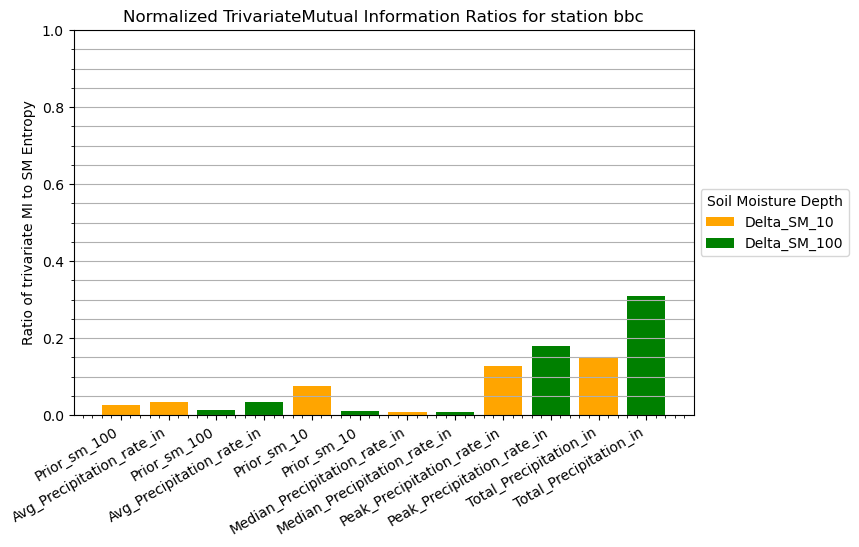

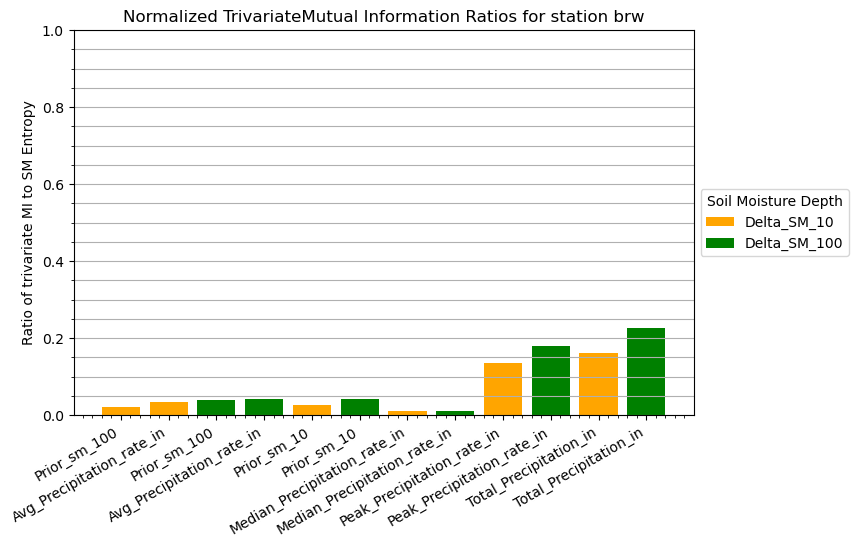

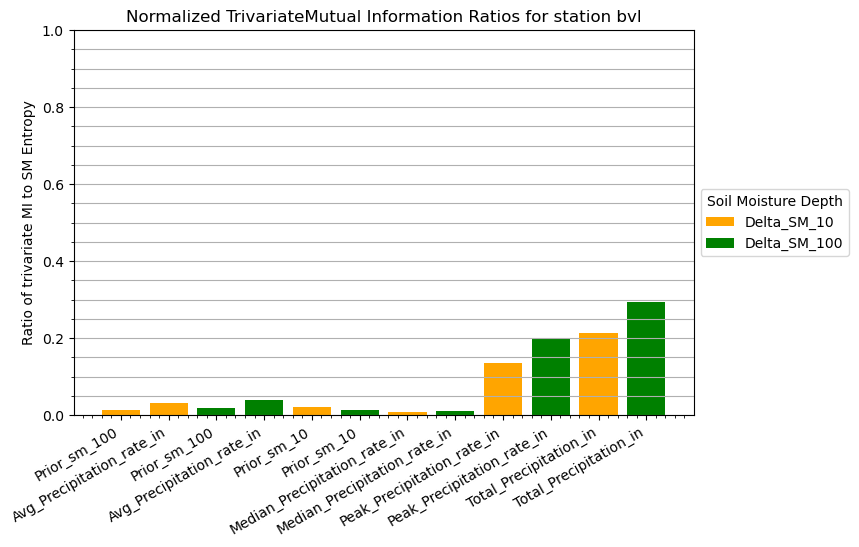

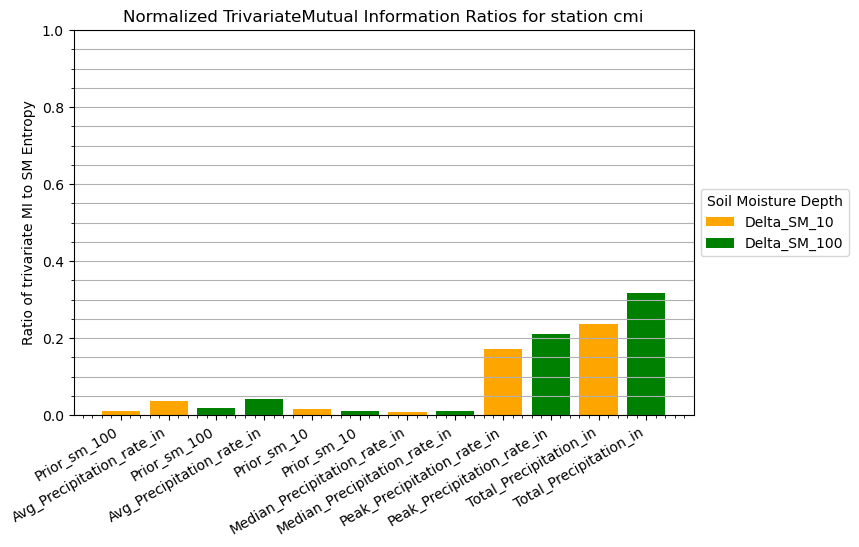

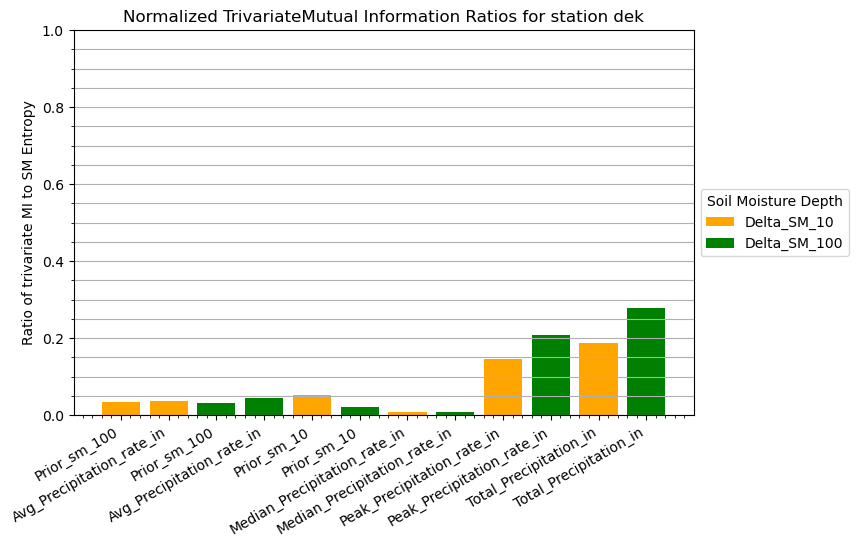

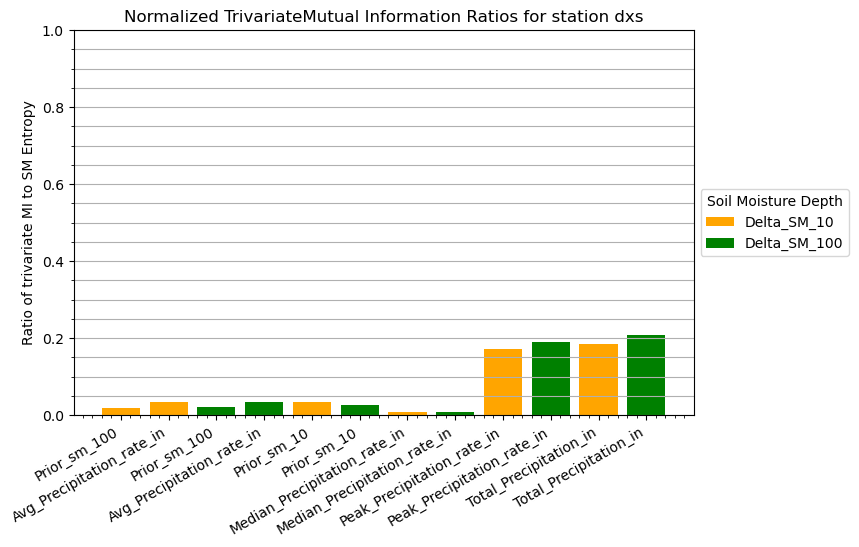

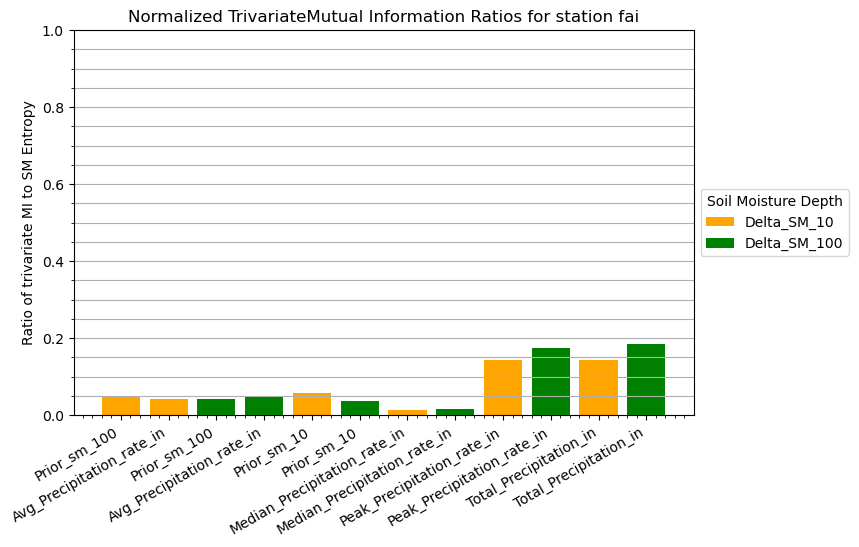

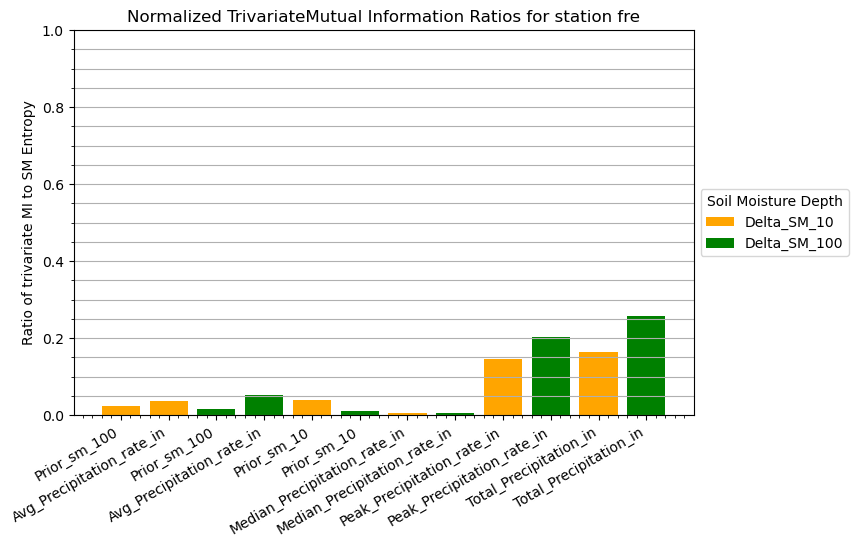

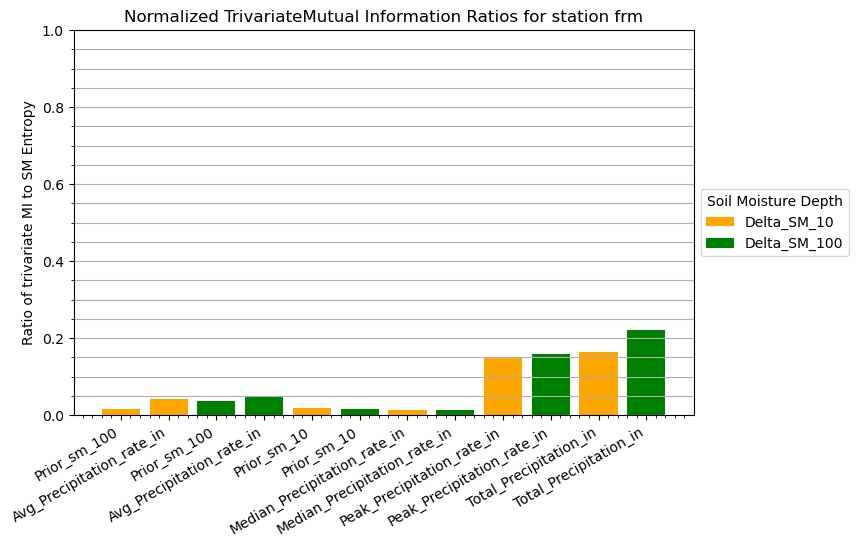

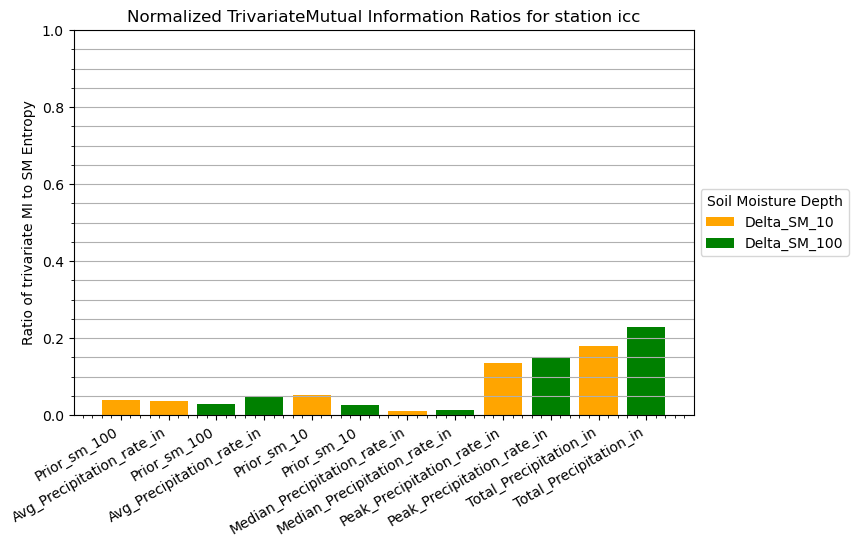

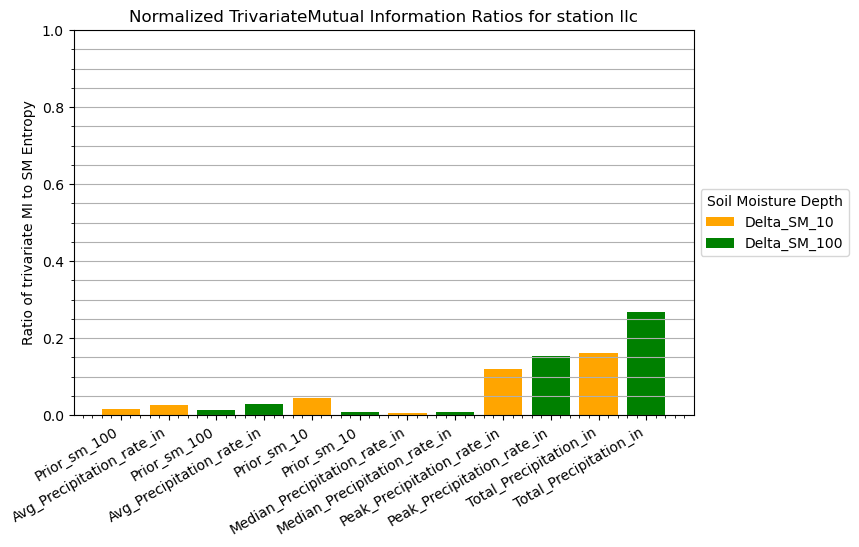

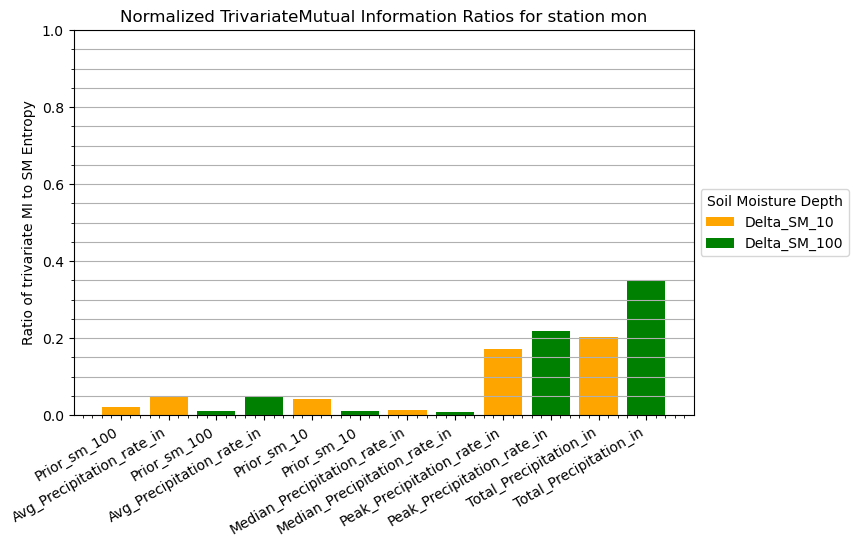

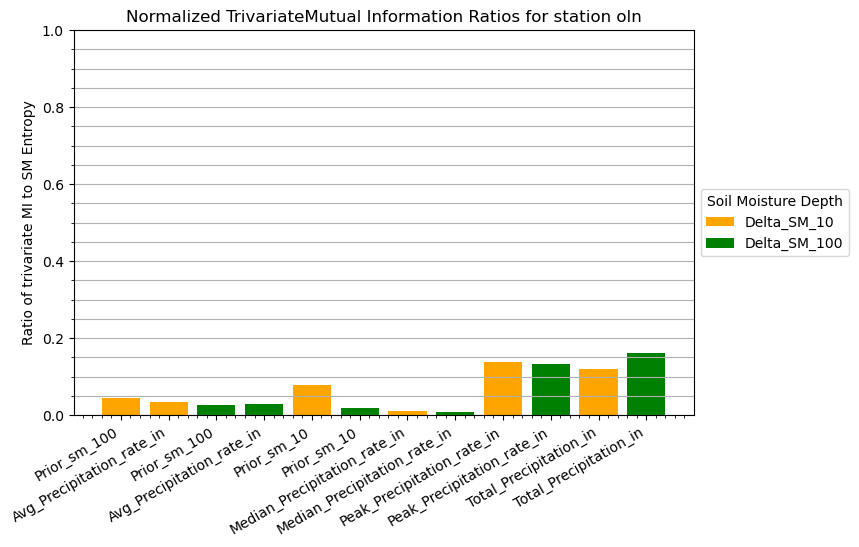

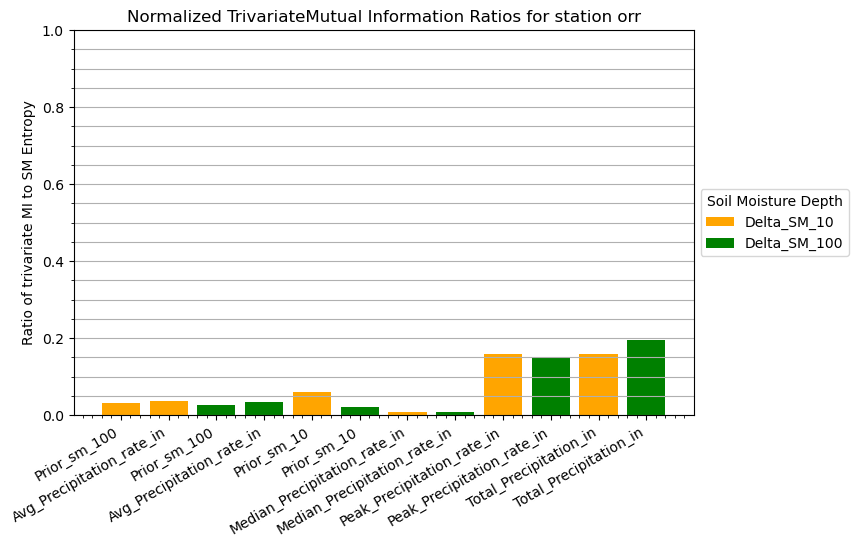

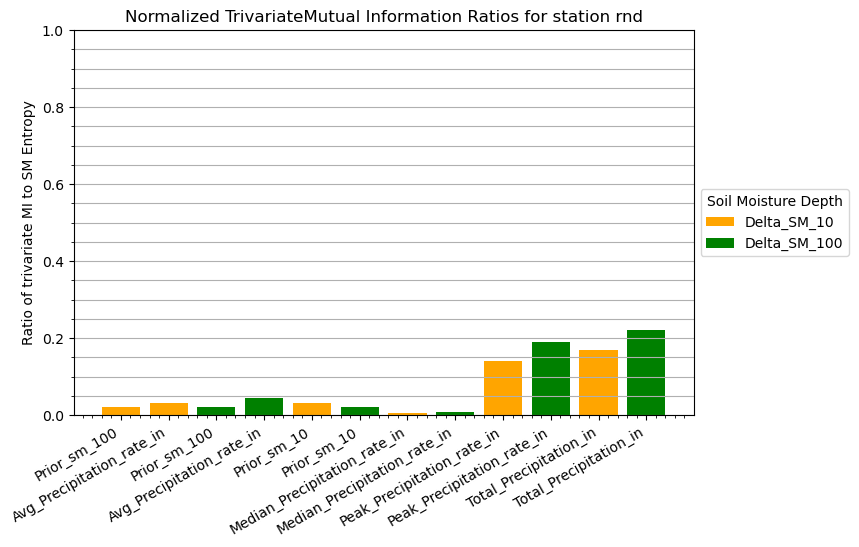

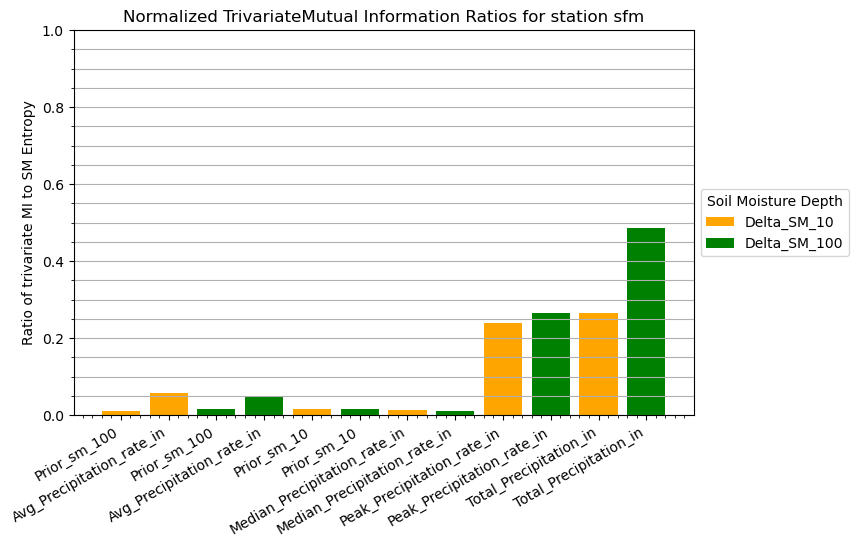

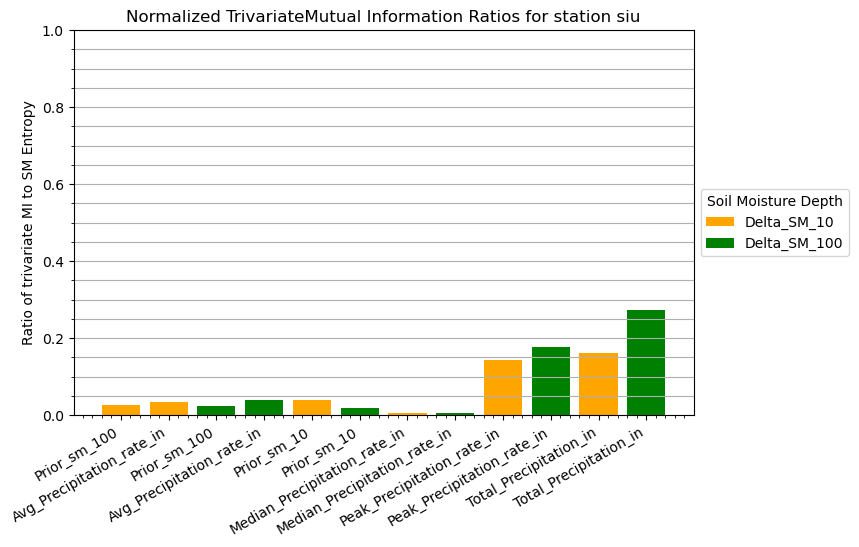

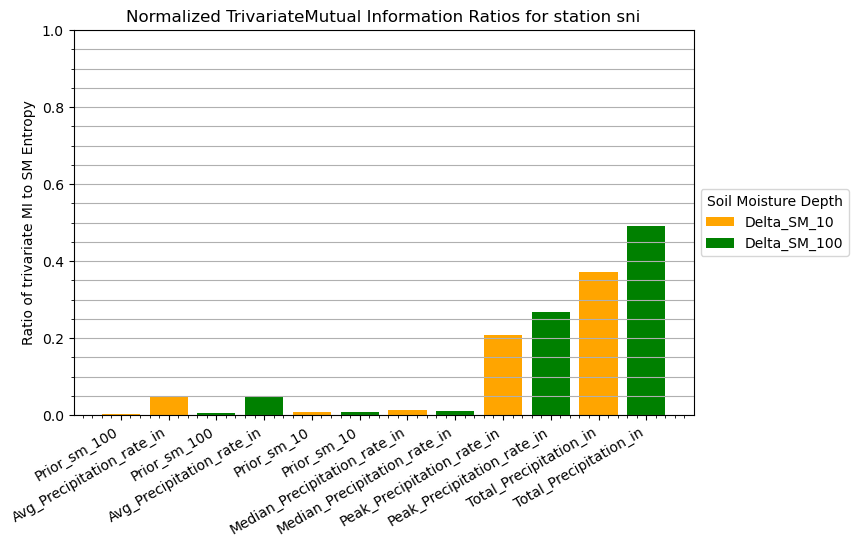

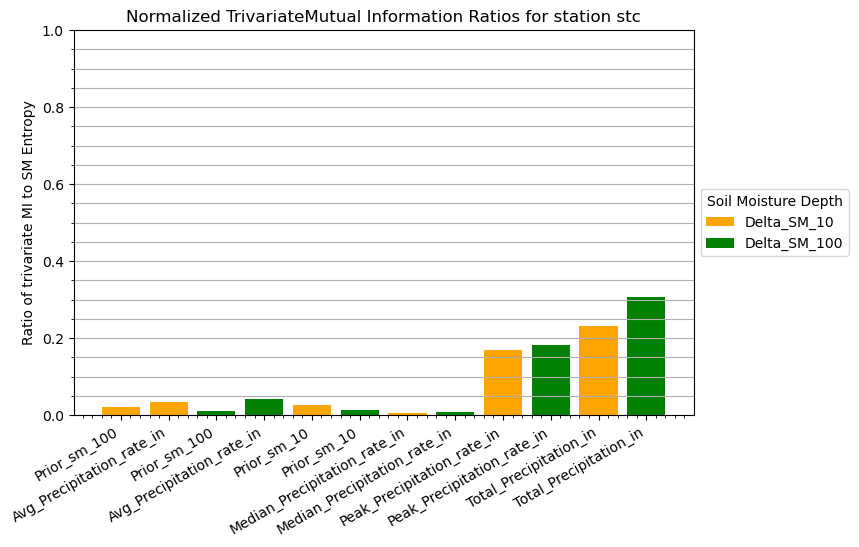

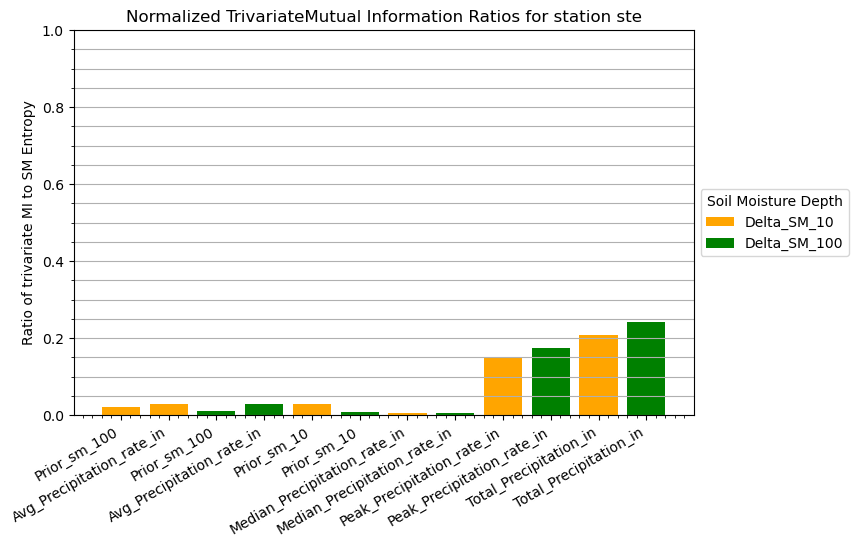

Peak max for sm 10: 2
Peak max for sm 100: 0


In [ ]:
from matplotlib.patches import Patch
stations = MIs.station.unique()


peak_10_largest = 0
peak_100_largest = 0

color_map = {
    'Delta_sm_10': 'orange',
    'Delta_sm_100': 'green'
            }

for s in stations:
    station_MI = MIs.loc[(MIs['station'] == s)]
    delta_ratios_to_plot = station_MI[(station_MI.MI_label.str.contains('Avg|Total|Peak|Median|Prior')) &
                                       ~station_MI.MI_label.str.contains('perPtot')]
    delta_ratios_to_plot = delta_ratios_to_plot[delta_ratios_to_plot.MI_label.str.contains('Delta')]
    col_labels = delta_ratios_to_plot['H(x)']
    color_labels = delta_ratios_to_plot['H(y)']
    
    sm_10_nopeak_ratios = delta_ratios_to_plot[~delta_ratios_to_plot.MI_label.str.contains('100') & 
                                             ~delta_ratios_to_plot.MI_label.str.contains('Peak')].iloc[:,6]
    
    sm_100_nopeak_ratios = delta_ratios_to_plot[delta_ratios_to_plot.MI_label.str.contains('100')& 
                                             ~delta_ratios_to_plot.MI_label.str.contains('Peak')].iloc[:,6]

    if (delta_ratios_to_plot[~delta_ratios_to_plot.MI_label.str.contains('100') & 
                            delta_ratios_to_plot.MI_label.str.contains('Peak')].iloc[:,6].values[0]) > sm_10_nopeak_ratios.max():
        peak_10_largest += 1
    if (delta_ratios_to_plot[delta_ratios_to_plot.MI_label.str.contains('100') & 
                            delta_ratios_to_plot.MI_label.str.contains('Peak')].iloc[:,6].values[0]) > sm_100_nopeak_ratios.max():
        peak_100_largest += 1
    

    fig, ax = plt.subplots(figsize = (8,5))
    bar_colors = color_labels.map(color_map).fillna('gray').tolist()
    ax.bar(delta_ratios_to_plot.MI_label, delta_ratios_to_plot.C_xy.astype(float), color = bar_colors)
    ax.set_ylim(0,1.0)
    ax.set_xticks(range(len(col_labels)))
    ax.set_xticklabels(labels= col_labels, rotation = 30, ha = 'right')  # rotate for readability

    ax.minorticks_on()
    ax.grid(which = 'both', axis = 'y')
    ax.set_title(f"Normalized Mutual Information Ratios for station {s}")
    legend_elements = [
        Patch(facecolor='orange', label='Delta_SM_10'),
        Patch(facecolor='green', label='Delta_SM_100')
    ]
    ax.legend(
            handles=legend_elements, 
            title="Soil Moisture Depth",
            loc = "center left",
            bbox_to_anchor = (1, 0.5)
            )
    #ax.set_xlabel("MI Label")
    ax.set_ylabel("Ratio of MI to Delta_SM Entropy")
    #ax.set_ticks()
    #plt.tight_layout()
    plt.show()

print('Peak max for sm 10:', peak_10_largest)
print('Peak max for sm 100:', peak_100_largest)

In [13]:
ptot_ratios_to_plot

,station,MI_label,mutual_information,H(x),C_yx,H(y),C_xy
575,ste,MI_Prior_sm_100_and_Delta_sm_100_perPtot,0.035,Prior_sm_100,0.009,Delta_sm_100_perPtot,0.017
576,ste,MI_Avg_Precipitation_rate_in_and_Delta_sm_100_...,0.024,Avg_Precipitation_rate_in,0.010,Delta_sm_100_perPtot,0.011
577,ste,MI_Prior_sm_100_and_Delta_sm_10_perPtot,0.054,Prior_sm_100,0.014,Delta_sm_10_perPtot,0.018
578,ste,MI_Avg_Precipitation_rate_in_and_Delta_sm_10_p...,0.021,Avg_Precipitation_rate_in,0.009,Delta_sm_10_perPtot,0.007
582,ste,MI_Prior_sm_10_and_Delta_sm_100_perPtot,0.023,Prior_sm_10,0.006,Delta_sm_100_perPtot,0.011
583,ste,MI_Prior_sm_10_and_Delta_sm_10_perPtot,0.063,Prior_sm_10,0.017,Delta_sm_10_perPtot,0.021
593,ste,MI_Peak_Precipitation_rate_in_and_Delta_sm_100...,0.047,Peak_Precipitation_rate_in,0.014,Delta_sm_100_perPtot,0.022
594,ste,MI_Peak_Precipitation_rate_in_and_Delta_sm_10_...,0.053,Peak_Precipitation_rate_in,0.016,Delta_sm_10_perPtot,0.017


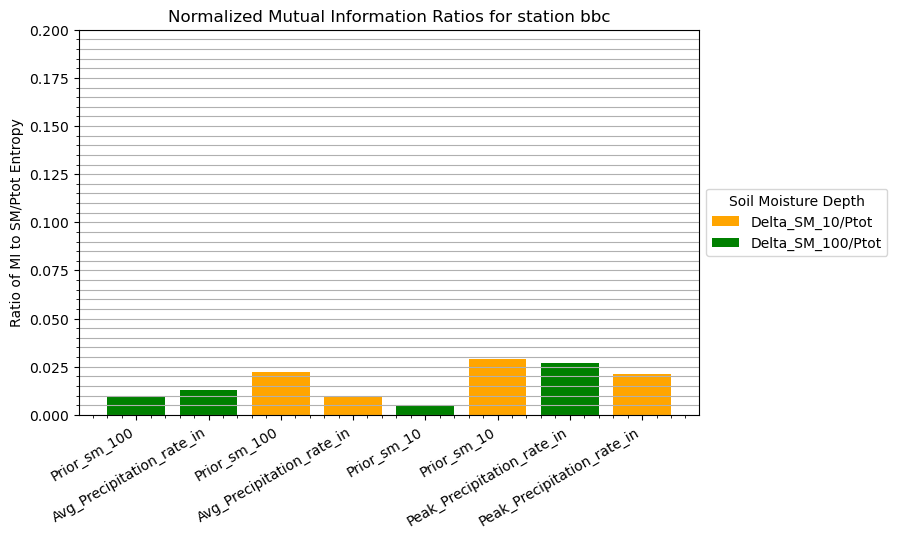

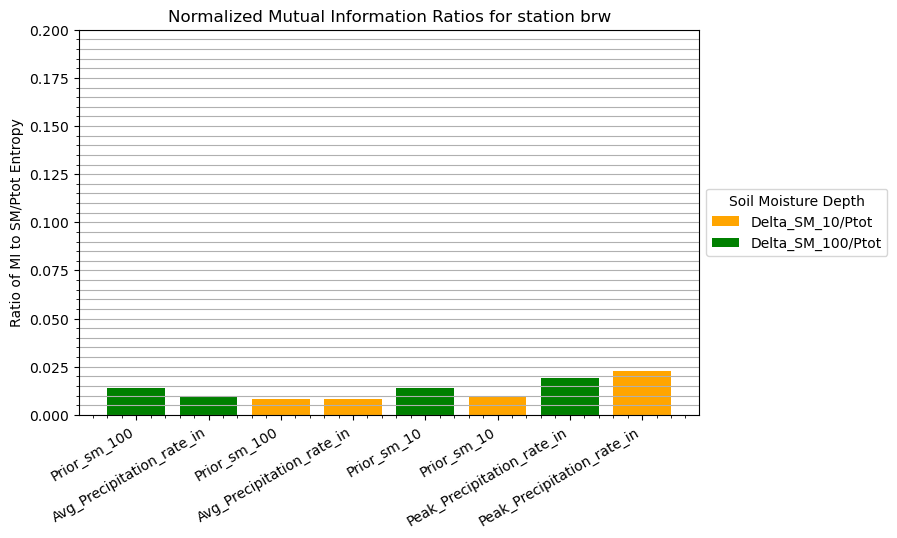

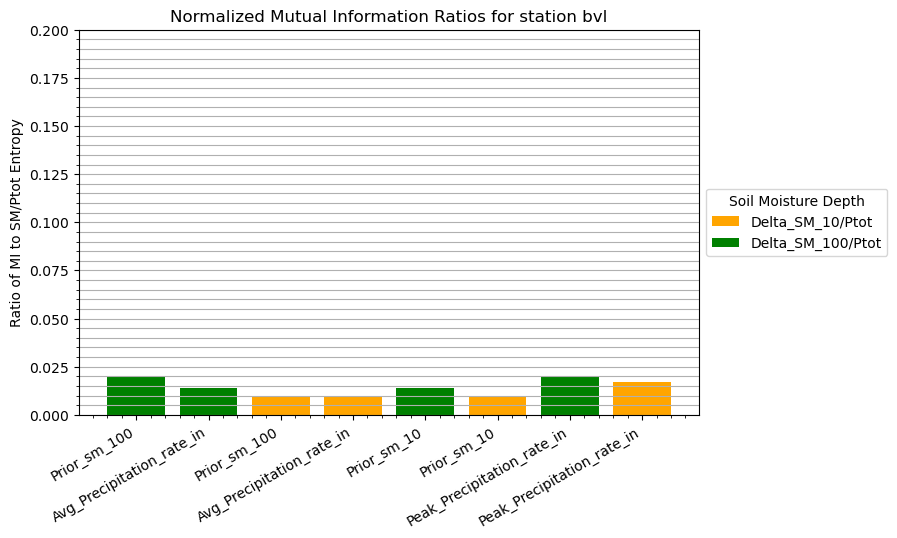

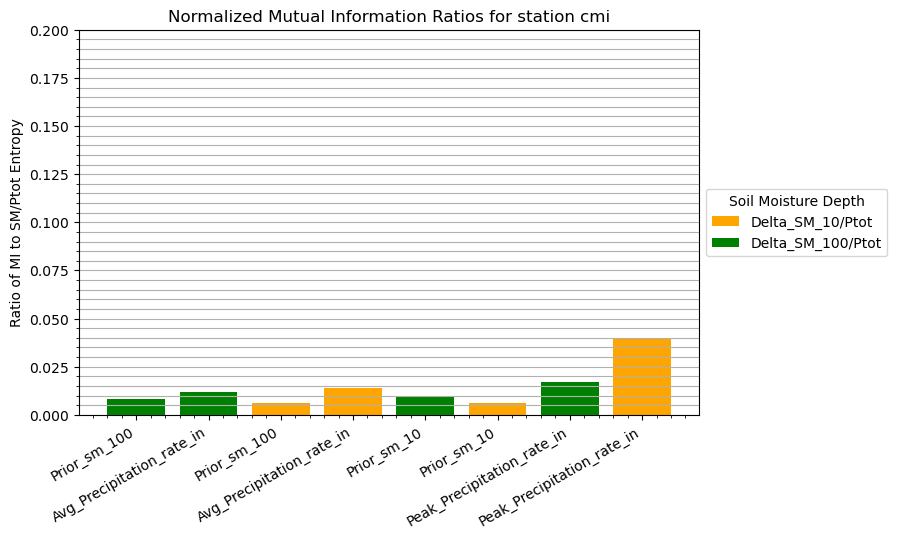

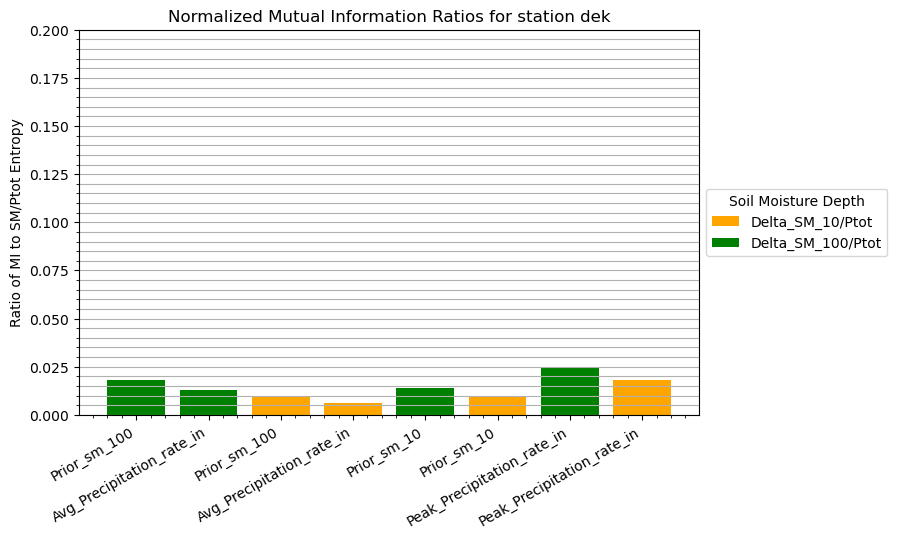

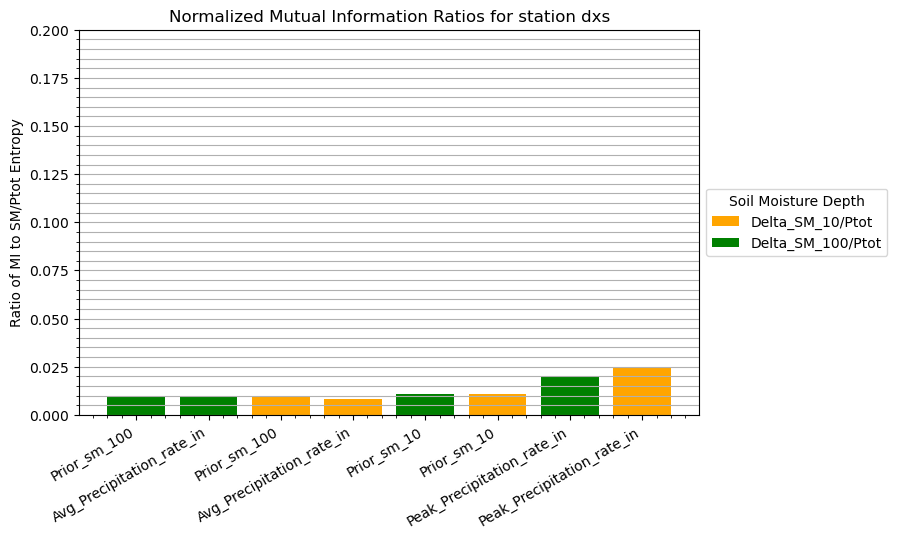

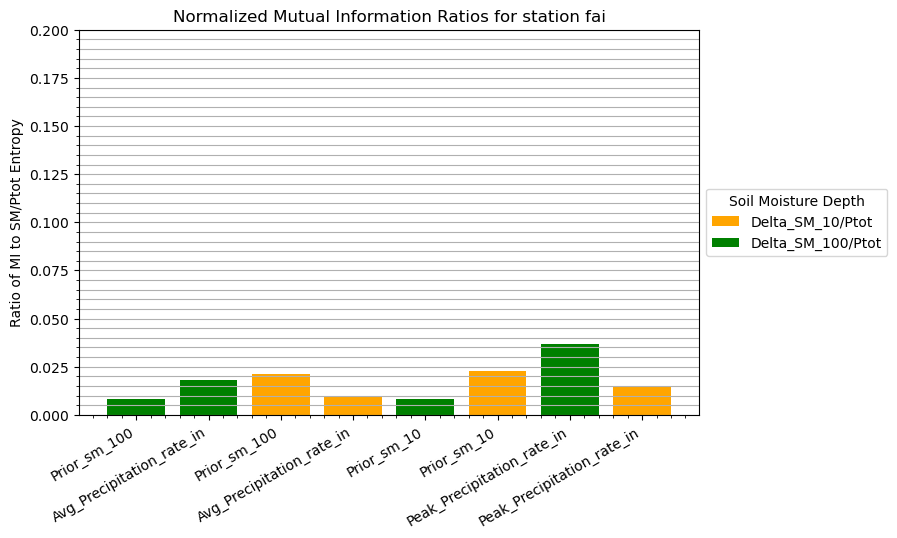

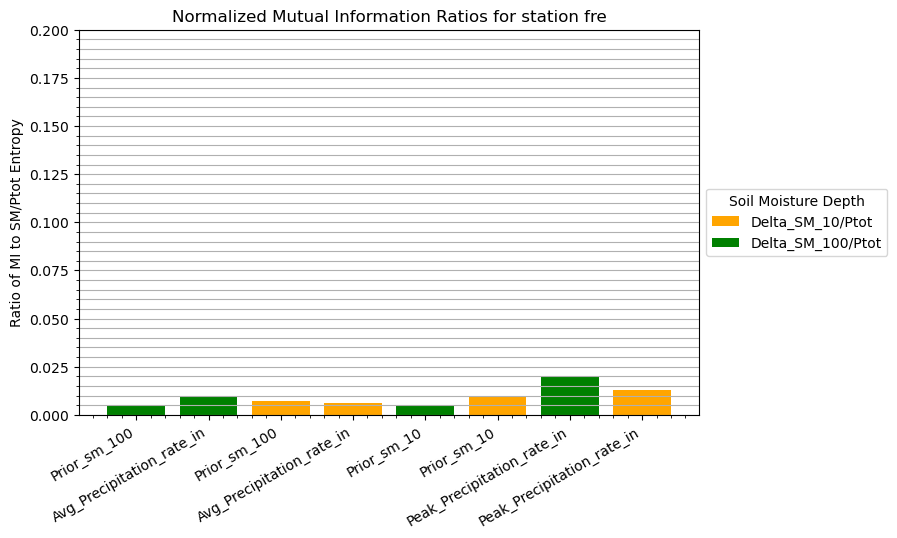

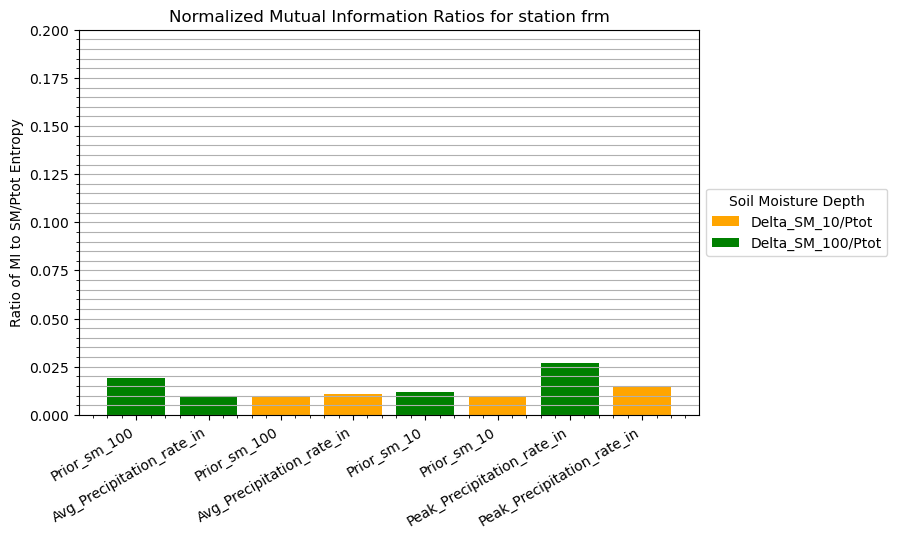

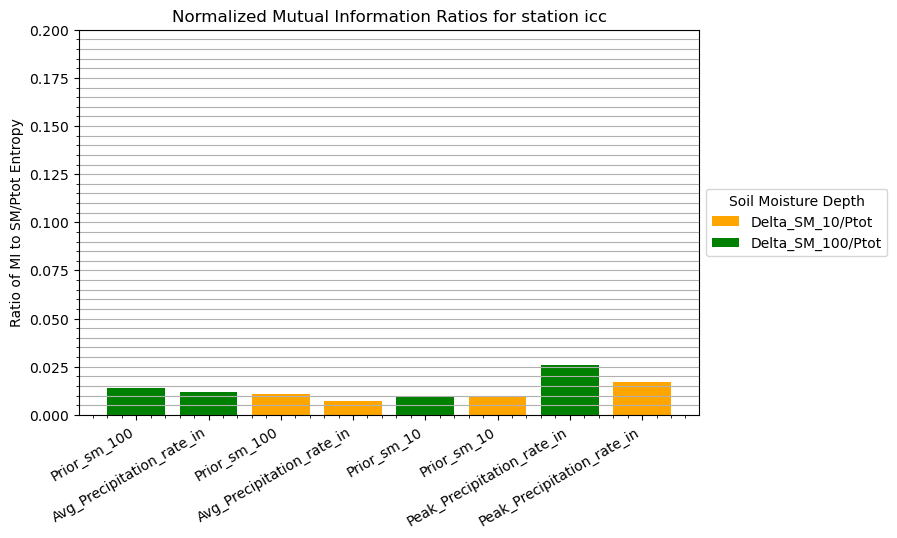

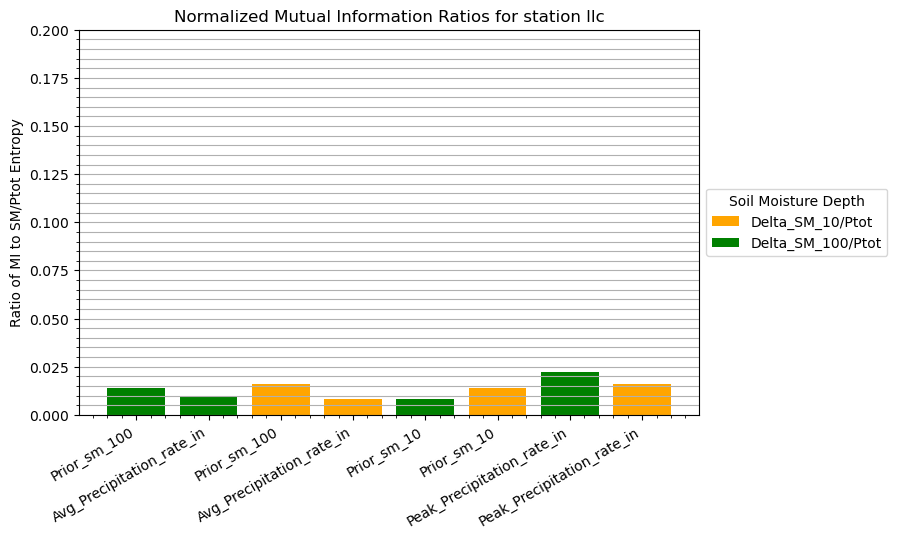

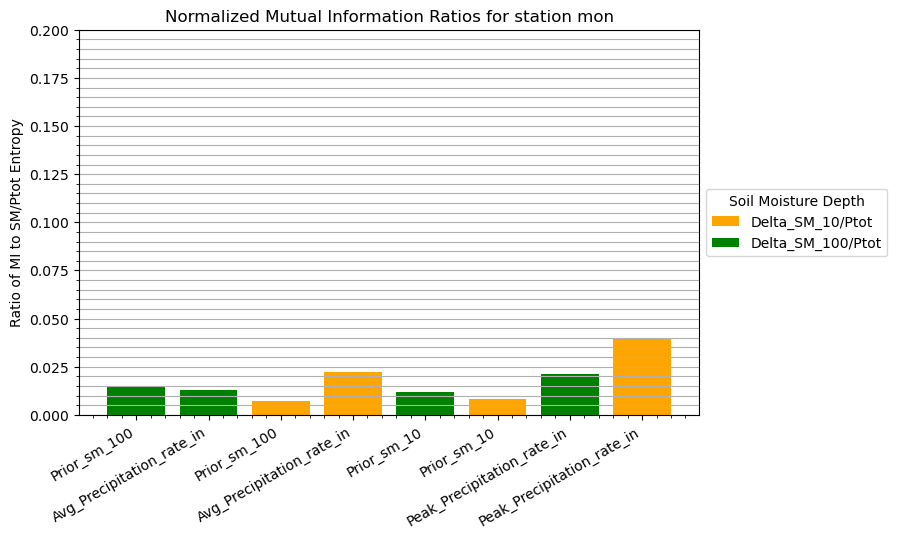

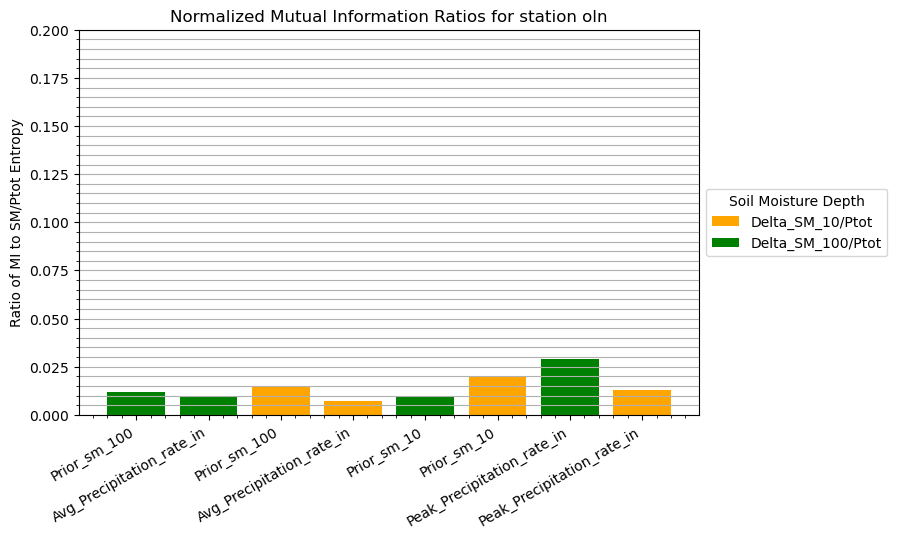

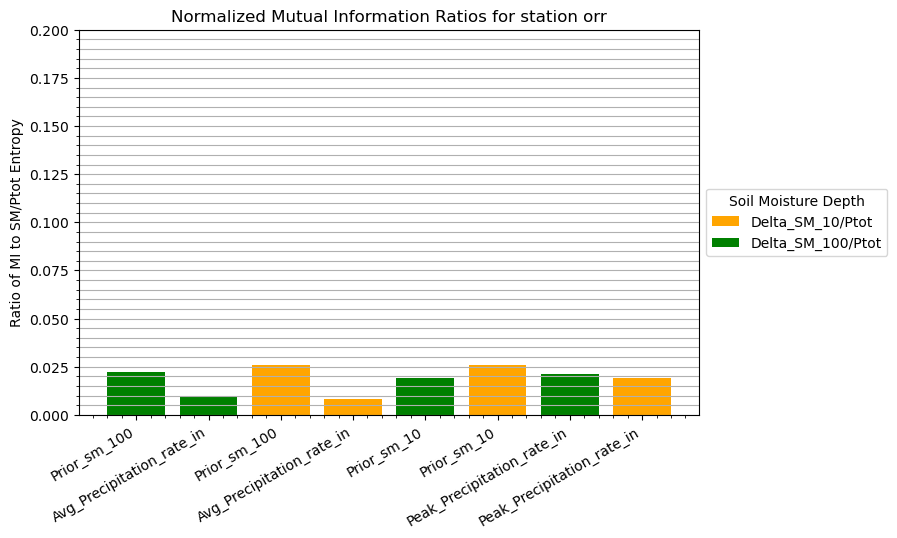

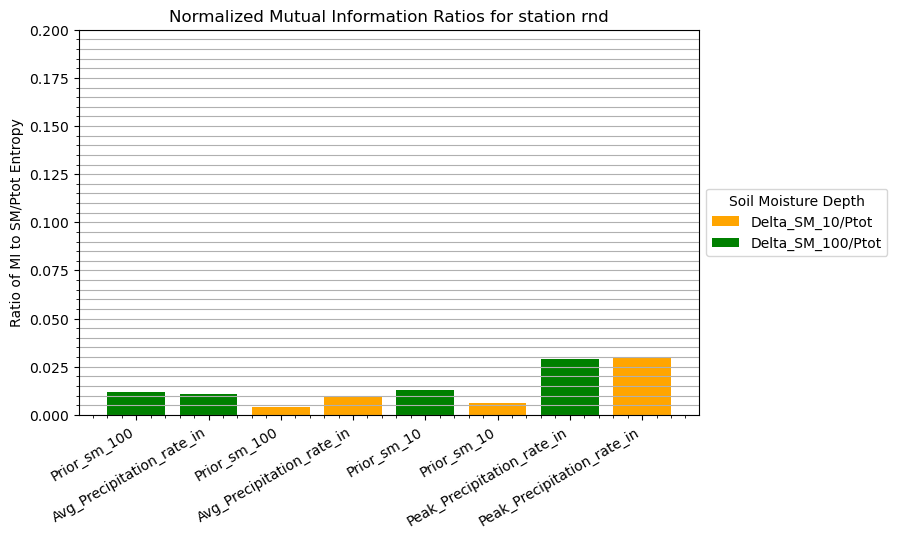

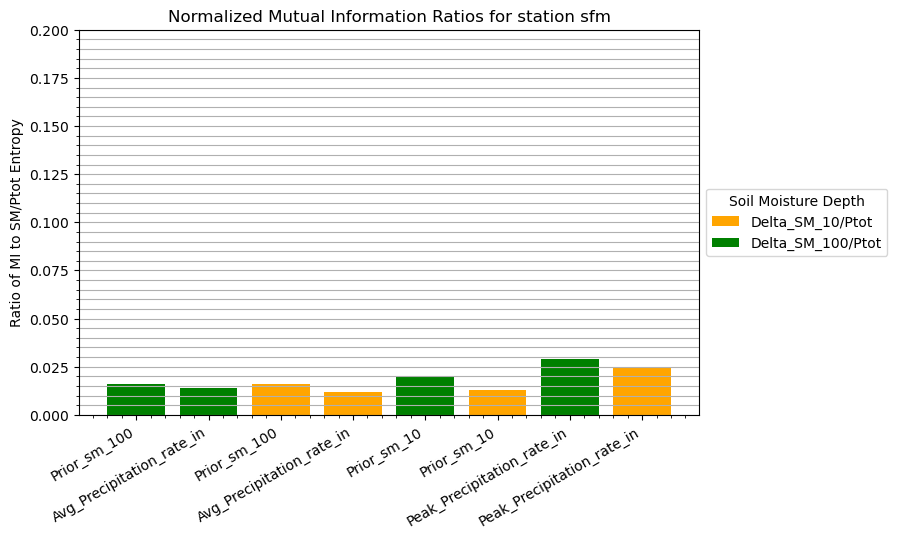

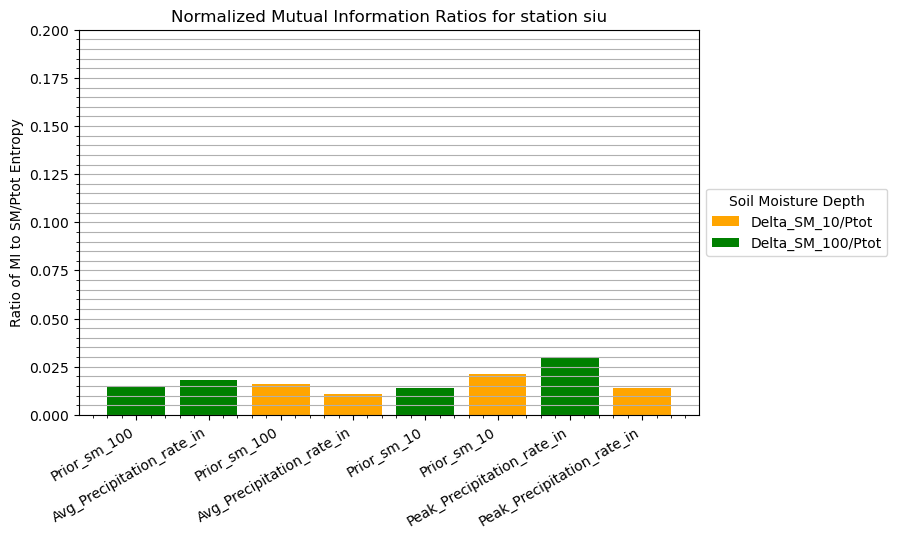

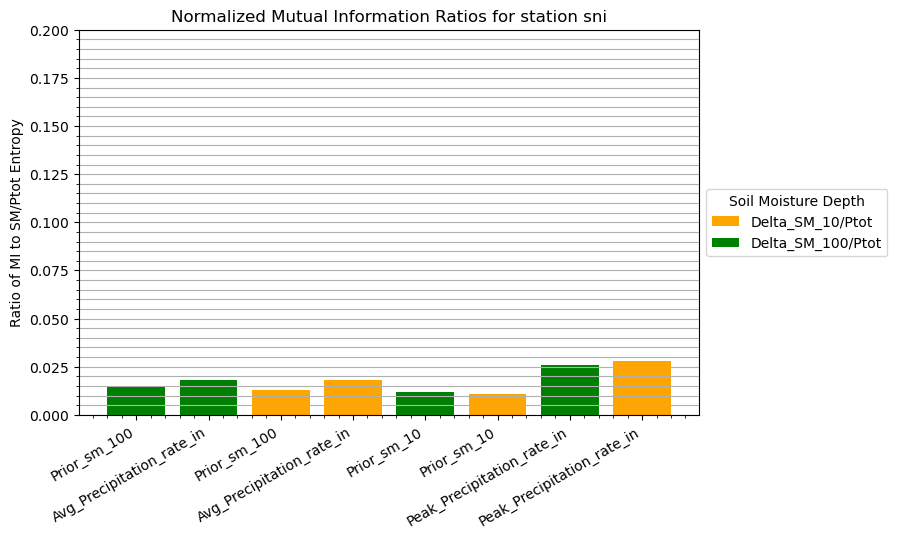

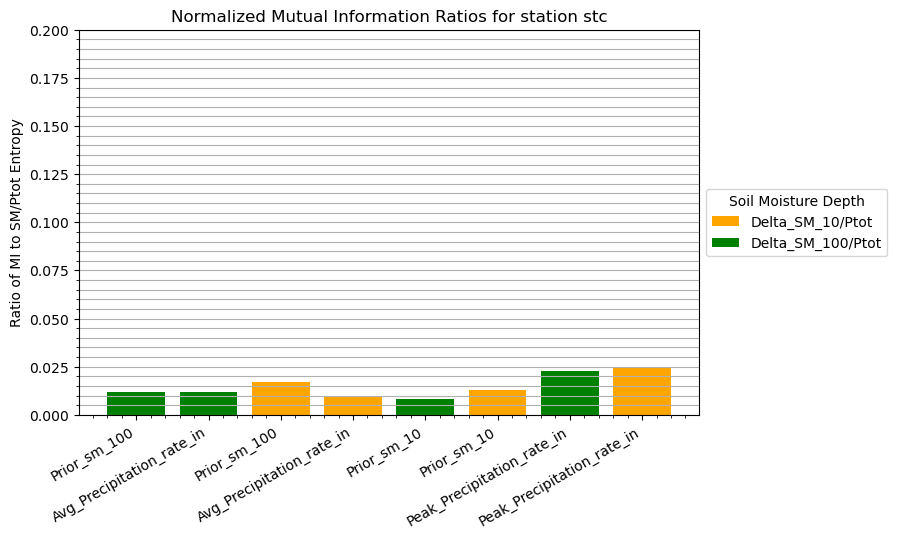

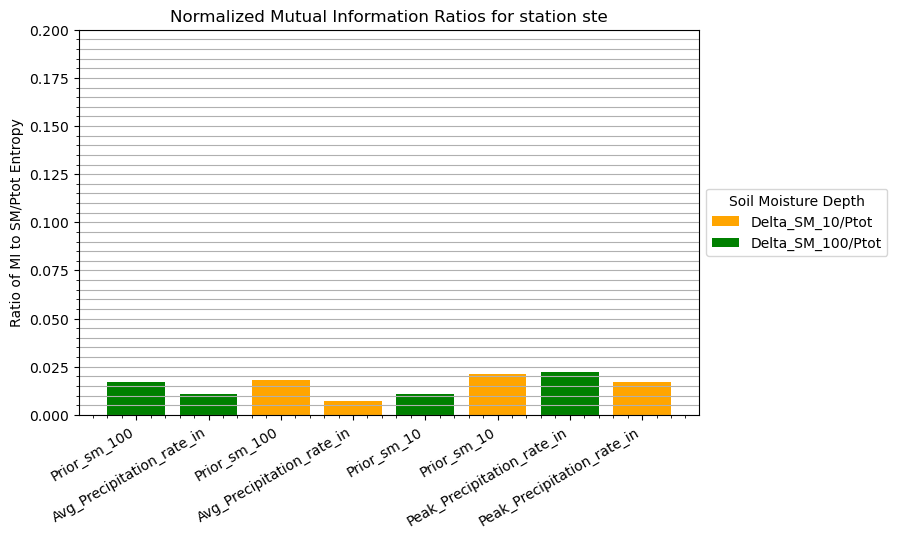

Peak max for sm 10: 14
Peak max for sm 100: 18


In [12]:
from matplotlib.patches import Patch
stations = MIs.station.unique()

peak_10_largest = 0
peak_100_largest = 0
color_map = {
    'Delta_sm_10_perPtot': 'orange',
    'Delta_sm_100_perPtot': 'green'
            }

for s in stations:
    station_MI = MIs.loc[(MIs['station'] == s)]
    ptot_ratios_to_plot = station_MI[(station_MI.MI_label.str.contains('Avg|Peak|Prior')) &(station_MI.MI_label.str.contains('Ptot'))]
    col_labels = ptot_ratios_to_plot['H(x)']
    color_labels = ptot_ratios_to_plot['H(y)']

    sm_10_nopeak_ratios = ptot_ratios_to_plot[~ptot_ratios_to_plot.MI_label.str.contains('100') & 
                                             ~ptot_ratios_to_plot.MI_label.str.contains('Peak')].iloc[:,6]
    sm_100_nopeak_ratios = ptot_ratios_to_plot[ptot_ratios_to_plot.MI_label.str.contains('100')& 
                                             ~ptot_ratios_to_plot.MI_label.str.contains('Peak')].iloc[:,6]

    if (ptot_ratios_to_plot[~ptot_ratios_to_plot.MI_label.str.contains('100') & 
                            ptot_ratios_to_plot.MI_label.str.contains('Peak')].iloc[:,6].values[0]) > sm_10_nopeak_ratios.max():
        peak_10_largest += 1
    if (ptot_ratios_to_plot[ptot_ratios_to_plot.MI_label.str.contains('100') & 
                            ptot_ratios_to_plot.MI_label.str.contains('Peak')].iloc[:,6].values[0]) > sm_100_nopeak_ratios.max():
        peak_100_largest += 1


    fig, ax = plt.subplots(figsize = (8,5))
    bar_colors = color_labels.map(color_map).fillna('gray').tolist()
    ax.bar(ptot_ratios_to_plot.MI_label, ptot_ratios_to_plot.C_xy.astype(float), color = bar_colors)
    ax.set_ylim(0,0.2)
    ax.set_xticks(range(len(col_labels)))
    ax.set_xticklabels(labels= col_labels, rotation = 30, ha = 'right')  # rotate for readability

    ax.minorticks_on()
    ax.grid(which = 'both', axis = 'y')
    ax.set_title(f"Normalized Mutual Information Ratios for station {s}")
    #ax.set_xlabel("MI Label")
    ax.set_ylabel("Ratio of MI to SM/Ptot Entropy")
    
    legend_elements = [
        Patch(facecolor='orange', label='Delta_SM_10/Ptot'),
        Patch(facecolor='green', label='Delta_SM_100/Ptot')
    ]
    ax.legend(
            handles=legend_elements, 
            title="Soil Moisture Depth",
            loc = "center left",
            bbox_to_anchor = (1, 0.5)
            )
    plt.show()

print('Peak max for sm 10:', peak_10_largest)
print('Peak max for sm 100:', peak_100_largest)

In [14]:
bbc_MI = MIs.loc[(MIs['station'] == 'sni')]
bbc_MI[(bbc_MI.MI_label.str.contains('Prior')) &
                                        ~(bbc_MI.MI_label.str.contains('Precipitation'))]

,station,MI_label,mutual_information,H(x),C_yx,H(y),C_xy
511,sni,MI_Prior_sm_100_and_Delta_sm_10,0.009,Prior_sm_100,0.002,Delta_sm_10,0.003
513,sni,MI_Prior_sm_100_and_Delta_sm_100,0.016,Prior_sm_100,0.004,Delta_sm_100,0.005
515,sni,MI_Prior_sm_100_and_Delta_sm_100_perPtot,0.039,Prior_sm_100,0.011,Delta_sm_100_perPtot,0.015
517,sni,MI_Prior_sm_100_and_Delta_sm_10_perPtot,0.037,Prior_sm_100,0.010,Delta_sm_10_perPtot,0.013
520,sni,MI_Prior_sm_10_and_Delta_sm_10,0.023,Prior_sm_10,0.006,Delta_sm_10,0.007
521,sni,MI_Prior_sm_10_and_Delta_sm_100,0.030,Prior_sm_10,0.008,Delta_sm_100,0.009
522,sni,MI_Prior_sm_10_and_Delta_sm_100_perPtot,0.031,Prior_sm_10,0.008,Delta_sm_100_perPtot,0.012
523,sni,MI_Prior_sm_10_and_Delta_sm_10_perPtot,0.032,Prior_sm_10,0.009,Delta_sm_10_perPtot,0.011


In [ ]:
from matplotlib.patches import Patch
stations = MIs.station.unique()

color_map = {
    'Prior_sm_10_': 'orange',
    'Prior_sm_100_': 'green'
}

for s in stations:
    station_MI = MIs.loc[(MIs['station'] == s)]
    priorsm_ratios_to_plot = station_MI[(station_MI.MI_label.str.contains('Prior')) &
                                        ~(station_MI.MI_label.str.contains('Precipitation'))]
    col_labels = priorsm_ratios_to_plot['H(y)']
    bar_colors = col_labels.map(color_map).fillna('orange').tolist()
    fig, ax = plt.subplots(figsize = (8,5))
    ax.bar(priorsm_ratios_to_plot.MI_label, priorsm_ratios_to_plot.C_xy.astype(float), color = bar_colors)
    ax.set_ylim(0,0.2)
    ax.set_xticks(range(len(col_labels)))
    ax.set_xticklabels(labels= col_labels, rotation = 30, ha = 'right')  # rotate for readability

    ax.minorticks_on()
    ax.grid(which = 'both', axis = 'y')
    ax.set_title(f"Normalized Mutual Information Ratios of Prior SM to Delta SM for station {s}")
    #ax.set_xlabel("MI Label")
    ax.set_ylabel("Ratio of MI to Delta SM")
    legend_elements = [
        Patch(facecolor='orange', label='Prior_SM_10'),
        Patch(facecolor='green', label='Prior_SM_100')
    ]
    ax.legend(
            handles=legend_elements, 
            title="Soil Moisture Depth",
            loc = "center left",
            bbox_to_anchor = (1, 0.5)
            )
    plt.show()